<img src="../logo.png" alt="Vegeta" width="240">

# Kestrel — the design study

**The one notebook to open for Kestrel**: the zero-stagger biplane quadrotor tailsitter in its three variants —
**4Q-1** (round struts, X bracing, the rotors as the only effectors), **4Q-2** (elevons, faired posts, no diagonals,
the reflexed section) and the proposed **4Q-3** (4Q-2's airframe with crow-brake elevons and reverse-capable drives) —
from the geometry and the mass budget to the transitions and a final assessment, on **inexpensive methods first**:
the mass table, Boreas's blade-element propulsion, the vortex lattice with Prandtl's biplane correlation, the drag
build-up, NeuralFoil's section polars, beam and truss statics, the reduced-order transition model. Where a
higher-fidelity answer exists on disk — the airframe in RANS with the propellers as actuator disks, the frame in
CalculiX — it is **read**, compared and labelled; it is never computed here.

**The rule this notebook follows (`side_labs/README.md`).** An analysis expected to take more than about 15–30
minutes — the whole campaign, not one case — is an explicit **workflow**, launched by the engineer from a shell and
monitored through its `run.log`; a notebook may *require* its output and must say exactly how to produce it, and must
never launch a solver, regenerate a missing analysis or hide expensive work behind an import or a loader. The Kestrel
workflows: `side_labs/kestrel/airframe_cfd.py` (Aeromant, rotor disks), `side_labs/kestrel/structure_fea.py` (Talos);
the resolved propeller stays in **`38_prop_lab`**, whose exported calibration is read here when it passed its gates.

**How every number is labelled.** *analytic* — closed-form physics; *empirical* — a correlation or surrogate with its
source and range (§ 5's table); *solver* — a Vegeta tool's numerical solution on its mesh or lattice; *validated* — a
converged solver result checked against a reference. An attached-flow formula is never a stall model, an unconverged
CFD case never a validation, and a NOT RUN stays NOT RUN with the analytical estimate visible beside it.

| § | section | method |
|---|---|---|
| 1 | prerequisites: what is on disk, its provenance and compatibility | — |
| 2 | geometry and layout, 3 variants | CAD (Dedalus) |
| 3 | mass budget, CG, inertia | estimate (component data + assumed densities) |
| 4 | propulsion and the hover | BEMT (solver) against momentum theory (analytic) |
| 5 | aerodynamics: lattice, drag build-up, sections, the polar; the CFD sweep read against it; the stall decision | solver + empirical; RANS where on file |
| 6 | trim, stability and control authority | lattice + empirical |
| 7 | performance and energy | solver + empirical |
| 8 | structure: plane frame and modes (analytic); FEA where on file | analytic; CalculiX where on file |
| 9 | transitions both ways, the remedies, the CFD correction | reduced-order model (solver) |
| 10 | which workflows to run next | — |
| 11 | final assessment, runtime, export | — |

## 1. Prerequisites

Workflow results are selected **by explicit run directory**, pinned in `notebooks/pins/43_kestrel_study.json` (`yn pin 43 K1 --variant 4Q-2 <run>`; the Yanus gate, `docs/yanus.md`, checks the pins, the tools and the files of the other notebooks first); a path alone proves nothing — each run's
`manifest.json` carries the design fingerprint it was made for (CAD parameters, mass, CG, propeller calibration,
source hashes) and `status.json` its state, and both are checked against this notebook's own build of the design.
**Required** inputs stop the notebook with the command that produces them; **optional** ones show NOT RUN and the
analytical estimate stays visible, labelled. `KESTREL_SCREENING=1` makes everything optional for a screening pass.
This notebook carries the **`yanus_auto` flag** (`auto=True` in `side_labs/flow.py`): a run it takes that is missing
is **produced by the gate itself, in screening quality** (`wf K1 --quality screening`, a coarse K11 mesh), prerequisites
first, with the output below the gate cell — so the notebook never stops here; what could not be run (no solver on
this machine, a failed script) is NOT RUN with the reason, and screening results are labelled *indicative*, never
*validated*. `yn auto 43 --dry-run` shows the plan from the shell; `YANUS_AUTO=0` switches the flag off for a session.

Runs live under `side_labs/runs/<book>/<chapter>/` — the **book** is the design (`kestrel`, code K), a **chapter**
one numbered study on it (K1 `airframe-sweep`, K2 `airframe-stall`, K3 `airframe-cruise`, K4 `airframe-transitions`
… K9 `frame`, K10 `joint`) — and `wf` (`side_labs/cli.py`) shows the tree, launches a chapter by code and watches
it. The first campaign's results (notebook 39, screening quality, 400 iterations) are imported into K1's folder by
`wf import_legacy`; they are what the pins point at until a workflow run replaces them (`wf notebook <run>`
prints the `yn pin` command).

In [ ]:
# DEBUG — ON BY DEFAULT: the expensive solvers are mocked (vegeta.mock: fixed numbers, seconds instead of hours,
# labelled MOCK). For real results set DEBUG = False here, or from the shell: VEGETA_DEBUG=0 jupyter nbconvert …
DEBUG = True
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [1]:
import json, math, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "../../designs")
import kestrel, kestrel_systems as ks, kestrel_flight as kf, kestrel_control as kc, kestrel_transition as kt, kestrel_cfd as kcfd
import kestrel_structure as kst, kestrel_drawings as kd, kestrel_loop as kl, kestrel_report as kr, kestrel2 as k2
import kestrel_campaigns as kcp, kestrel_study as kstu
from vegeta import dedalus

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40)
CLOCK = kstu.Stopwatch()
OUT = Path("../output/43_kestrel_study"); OUT.mkdir(parents=True, exist_ok=True)
MAIN = kstu.MAIN                                   # the variant the required inputs and the final assessment are about
VARIANTS = kstu.VARIANTS
SCREENING = os.environ.get("KESTREL_SCREENING") == "1"

# ---- the side-lab results, by Porunga key (designs/kestrel_keys.py): each is looked up in the local cache
#      (cache/porunga, $PORUNGA_DIR); a missing required one stops here with the side-lab command to run — this
#      notebook never starts one. In DEBUG it reads the mock entries, labelled MOCK, never the real ones.
FP = {v: kcp.fingerprint(v) for v in VARIANTS}
REQUIRED = {t[:3] for t in kstu.TAKES if t[3] and not SCREENING}
print(f"main variant {MAIN} | screening {SCREENING} | mock {DEBUG} | required: {sorted(REQUIRED) or 'nothing'}")
PREREQ, SUMM = kstu.inputs_from_cache(VARIANTS, mock=DEBUG, screening=SCREENING or DEBUG, fingerprints=FP)   # DEBUG: missing results are NOT RUN, not an error
display(PREREQ)
CLOCK.lap("1 prerequisites")

main variant 4Q-2 | screening True | required: nothing


,role,selection,status,provenance,compatibility,usable
input,,,,,,
prop_lab calibration (notebook 38),optional,designs/data/prop_lab.json,NOT RUN or rejected: Boreas's generic blade section and De Young's normal force,38_prop_lab,,False
drive tables (Boreas),required,designs/data/kestrel_drive.json,"on file for this motor, propeller, battery and calibration",kestrel_systems.compute_drive_table,"keyed on motor, propeller, battery, calibration",True
section polars (Zephyr / NeuralFoil),optional,designs/data/kestrel_sections.json,NeuralFoil polars on file,kestrel_section.table,"keyed on candidates, flap chord, n_crit",True
"airframe CFD, 4Q-1, sweep",optional,side_labs/runs/kestrel/airframe-sweep/legacy_20261016_4Q-1_39_kestrel_tests,"completed: 29 of 29 solved, 0 converged","imported from kestrel_cfd_results.json (39_kestrel_tests, 2026-10-16, screening, 400 it)",warnings: fingerprint assumed from the current source: the legacy results file recorded none (the CAD para...,True
"airframe CFD, 4Q-2, sweep",optional,side_labs/runs/kestrel/airframe-sweep/legacy_20261016_4Q-2_39_kestrel_tests,"completed: 29 of 29 solved, 1 converged","imported from kestrel_cfd_results.json (39_kestrel_tests, 2026-10-16, screening, 400 it)",warnings: fingerprint assumed from the current source: the legacy results file recorded none (the CAD para...,True
"airframe CFD, 4Q-3, sweep",optional,—,not selected,,,False


runs on disk under side_labs/runs/<book>/<chapter>/: 2
  kestrel   airframe-sweep         4Q-2  completed  legacy_20261016_4Q-2_39_kestrel_tests
  kestrel   airframe-sweep         4Q-1  completed  legacy_20261016_4Q-1_39_kestrel_tests
(wf runs lists them with their chapter codes)


1.7

## 2. Geometry and layout

Both wings share one leading-edge station (zero stagger is built into the CAD, not a parameter); the pod spans the gap
with the camera in the nose and the payload capsule on the axis; four fixed propellers thrust along the pod. The layout
rules — the discs clear each other and the pod, the propeller plane is ahead of the leading edge, the feet reach aft of
the pod — are checked before anything is computed. The variants differ in their effectors, struts, bracing and section;
the wings, pod and rotors are the same, so the lattice is computed once.

Kestrel-4Q-1: layout rules all hold
Kestrel-4Q-2: layout rules all hold
Kestrel-4Q-3: layout rules all hold


,Kestrel-4Q-1,Kestrel-4Q-2,Kestrel-4Q-3
parameters that differ,,,
bracing,as 4Q-1,posts,posts
strut_fairing,as 4Q-1,True,True
elevons,as 4Q-1,True,True
elevon_chord,as 4Q-1,as 4Q-1,0.32
elevon_inner_y,as 4Q-1,as 4Q-1,250.0


,span,chord,gap,h,x_le,x_te,x_ac,x_spar,S_wing,S_ref,AR_wing,gap_chord,gap_span,R_prop,A_disc,motor_y,prop_x,prop_ahead_of_le,prop_gap,prop_to_pod,prop_beyond_tip,pod_length,pod_width,pod_height,post_length,diagonal_length,x_feet,fin_height,ventral_height,fin_tip_chord,fin_root_x,foot_rod_length,elevons,elevon_cf,elevon_y_in,elevon_span_side,x_hinge,S_elevon,diagonals,posts
"layout [m, m²]",1.0,0.14,0.28,0.14,0.2,0.34,0.235,0.242,0.14,0.28,7.1429,2.0,0.28,0.1143,0.041,0.39,0.125,0.075,0.0514,0.2207,0.0043,0.47,0.11,0.28,0.28,0.4366,0.54,0.19,0.15,0.09,0.28,0.256,1,0.28,0.275,0.225,0.3008,0.0353,0,2


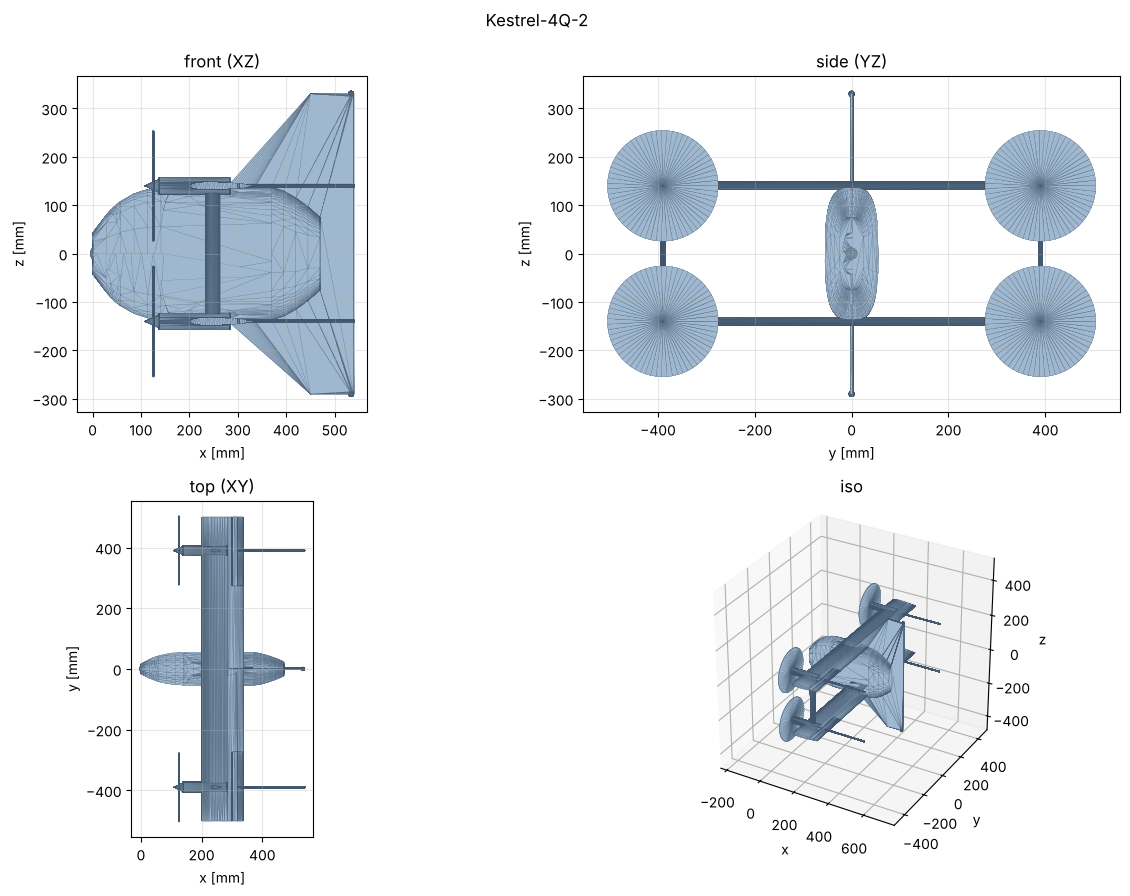

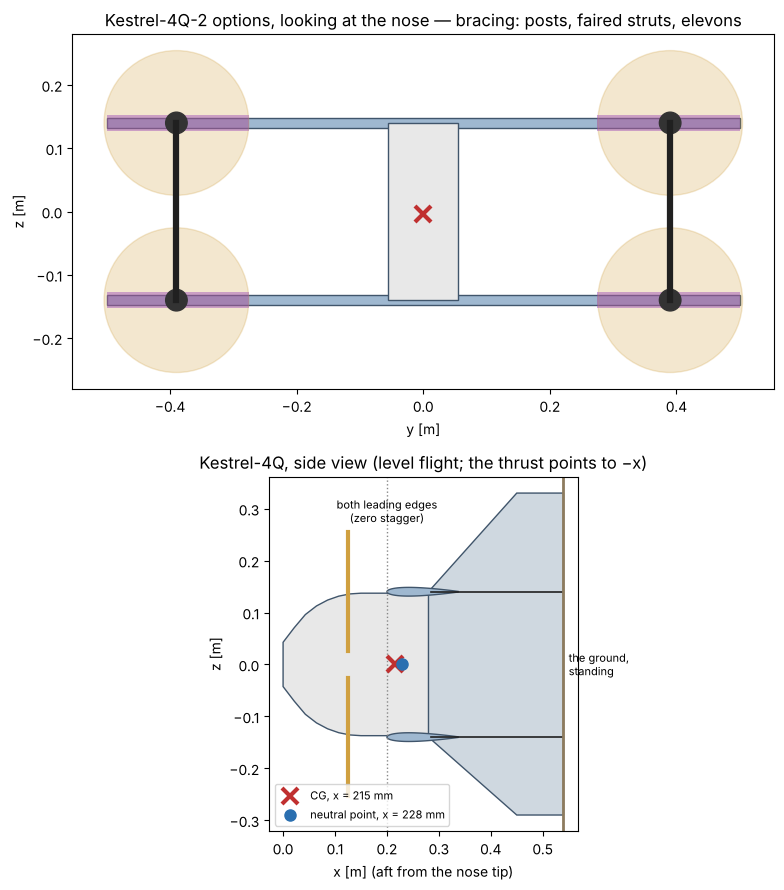

13.5

In [2]:
design = dedalus.load_design("../../designs/kestrel.py:Kestrel4Q")
SETS = kstu.build_all(VARIANTS)                    # per variant: parameters, layout, mass table, CG, polar, neutral point, hover, cruise table, transition vehicle
S = SETS[MAIN]; P, L = S["p"], S["L"]
for v, s in SETS.items():
    print(f"Kestrel-{v}: layout rules {'all hold' if not s['layout_rules'] else s['layout_rules']}")
diff = {v: {k: s["p"][k] for k in s["p"] if s["p"][k] != SETS["4Q-1"]["p"][k] and k not in kestrel.PER_CALL} for v, s in SETS.items()}
display(pd.DataFrame({f"Kestrel-{v}": d for v, d in diff.items()}).fillna("as 4Q-1").rename_axis("parameters that differ"))
lay = pd.Series({k: v for k, v in L.items() if isinstance(v, (int, float))}, name="layout [m, m²]")
display(lay.round(4).to_frame().T)
g = design.generate(part="aircraft", **{k: P[k] for k in ("elevons", "elevon_chord", "elevon_inner_y", "strut_fairing", "bracing")})
dedalus.plot_views(g, figsize=(13, 9)); plt.suptitle(f"Kestrel-{MAIN}", y=0.99); plt.show()
fig, ax = plt.subplots(2, 1, figsize=(12, 9))
(kd.front_view_4q2 if P["elevons"] else kd.front_view)(P, cg=S["ci"], ax=ax[0]); kd.side_view(P, x_cg=S["ci"]["x_cg"], x_np=S["np"]["x_np"], ax=ax[1]); plt.tight_layout(); plt.show()
CLOCK.lap("2 geometry")

## 3. Mass budget, centre of gravity, inertia

Bought parts from `kestrel_systems.COMPONENTS`, the structure from the layout's lengths and areas with assumed
densities (balsa-composite panels, carbon tubes, printed joints, a foam-and-film strut sleeve), a growth margin. The
battery slides on the pod's floor to put the CG at 10 % of the chord behind the leading edge; § 6 says whether that
margin is right. **Method: estimate** — component masses are catalogue values, structural densities are assumptions
(±15 % on the structure's share).

In [3]:
display(kstu.mass_groups(SETS).round(3))
mt = pd.DataFrame(S["table"]).set_index("item")[["mass_kg", "x", "y", "z", "group"]]
display(mt.assign(mass_g=lambda d: d.mass_kg * 1000).drop(columns="mass_kg").round(3))
CI = S["ci"]
print(f"Kestrel-{MAIN}: take-off mass {CI['mass_kg']:.3f} kg; CG x {CI['x_cg'] * 1000:.1f} mm (battery at {CI['battery_x'] * 1000:.0f} mm, "
      f"{'at its stop' if CI['battery_clipped'] else 'inside its bay'}), z {CI['z_cg'] * 1000:+.1f} mm; Ixx {CI['Ixx']:.4f}, Iyy {CI['Iyy']:.4f}, Izz {CI['Izz']:.4f} kg·m²")
CLOCK.lap("3 mass")

,propulsion,structure,systems,payload,margin
Kestrel-4Q-1,0.736,0.625,0.160,0.105,0.06
Kestrel-4Q-2,0.736,0.542,0.208,0.105,0.06
Kestrel-4Q-3,0.736,0.542,0.208,0.105,0.06


,x,y,z,group,mass_g
item,,,,,
motor M1,0.150,-0.390,0.140,propulsion,66.000
propeller M1,0.125,-0.390,0.140,propulsion,14.000
ESC M1,0.220,-0.390,0.140,propulsion,14.000
nacelle M1,0.205,-0.390,0.140,structure,12.000
motor M2,0.150,0.390,0.140,propulsion,66.000
propeller M2,0.125,0.390,0.140,propulsion,14.000
ESC M2,0.220,0.390,0.140,propulsion,14.000
nacelle M2,0.205,0.390,0.140,structure,12.000
motor M3,0.150,-0.390,-0.140,propulsion,66.000


Kestrel-4Q-2: take-off mass 1.651 kg; CG x 215.4 mm (battery at 220 mm, at its stop), z -4.6 mm; Ixx 0.1131, Iyy 0.0232, Izz 0.1040 kg·m²


0.0

## 4. Propulsion and the hover

One drive: a 9×6 propeller on a 2216-class 880 KV motor on 4S. **Boreas** (blade-element momentum theory with a
generic thin cambered section, the motor's first-order model, the battery) gives the drive tables the transition
model reads: the full thrust $T_{max}(V)$, the torque-to-thrust ratio $\kappa = Q/T$ (the only lever about the thrust
axis without surfaces) and the electrical power $P(T, V)$. The tables are **on file** (`data/kestrel_drive.json`,
keyed on the components and the calibration) — the prerequisite table said whether they would be computed here.

The analytic check is momentum theory: a rotor of disc area $A$ carrying thrust $T$ induces
$v_i = \sqrt{T / 2\rho A}$ and needs the ideal power $P_i = T\,v_i = T^{3/2}/\sqrt{2\rho A}$; the real rotor takes
$P_i / FM$ with a figure of merit of 0.5–0.65 for a 9-inch propeller, and the drive $\approx 0.8$ of that again in
electrical terms. When **prop_lab** (notebook 38) has a calibration on file that passed its gates, the blade section's
$c_l$ and $c_d$ scales and the normal-force factor are applied in `kestrel_systems.propulsion`; without it the generic
section reads ~25 % low on static thrust, which keeps the control margins conservative.

prop_lab: NOT RUN or rejected: the generic blade section


,thrust_N,rpm,current_A,electrical_W,throttle,figure_of_merit,T_max_N,T_W,kappa_m,total_W
"hover, one drive [Boreas BEMT, solver]",,,,,,,,,,
Kestrel-4Q-1,4.1340,6709.9298,6.6538,55.1622,0.5602,0.5649,11.9606,2.8932,0.0162,220.6488
Kestrel-4Q-2,4.0481,6639.8034,6.5259,53.4979,0.5539,0.5649,11.9606,2.9546,0.0162,213.9914
Kestrel-4Q-3,4.0481,6639.8034,6.5259,53.4979,0.5539,0.5649,11.9606,2.9546,0.0162,213.9914


,Kestrel-4Q-2: momentum theory [analytic] beside Boreas
thrust per rotor [N],4.048
disc loading [N/m²],98.629
induced velocity [m/s],6.345
"ideal power, one rotor [W]",25.684
"electrical at FM 0.6, η 0.8, four rotors [W]",214.034
Boreas FM,0.565
"Boreas electrical, four rotors [W]",213.991


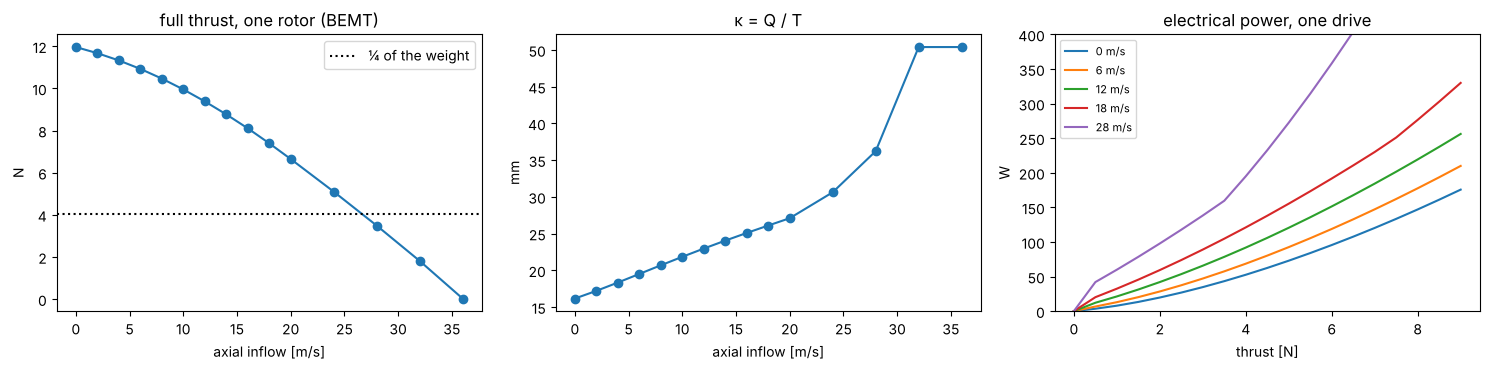

0.4

In [4]:
PL = ks.prop_lab_calibration()
print("prop_lab:", (f"calibration on file — cl ×{PL['cl_scale']:.3f}, cd ×{PL['cd_scale']:.3f}, CNα ×{PL['cn_factor']:.3f}" if PL["on_file"] else "NOT RUN or rejected: the generic blade section"))
DR = S["veh"].drive
display(pd.DataFrame({f"Kestrel-{v}": s["hover"] for v, s in SETS.items()}).T.round(4).rename_axis("hover, one drive [Boreas BEMT, solver]"))
display(pd.Series(kstu.hover_analytic(S), name=f"Kestrel-{MAIN}: momentum theory [analytic] beside Boreas").round(3).to_frame())
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(DR.V, DR.T_max, "o-"); ax[0].axhline(CI["mass_kg"] * ks.G / 4, color="k", ls=":", label="¼ of the weight"); ax[0].set(xlabel="axial inflow [m/s]", ylabel="N", title="full thrust, one rotor (BEMT)"); ax[0].legend()
ax[1].plot(DR.V, np.array(DR.kappa) * 1000, "o-"); ax[1].set(xlabel="axial inflow [m/s]", ylabel="mm", title="κ = Q / T")
for v in DR.V[::3]:
    j = list(DR.V).index(v); ax[2].plot(DR.T, DR.P[j], label=f"{v:g} m/s")
ax[2].set(xlabel="thrust [N]", ylabel="W", title="electrical power, one drive", ylim=(0, 400)); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
CLOCK.lap("4 propulsion")

## 5. Aerodynamics: the lattice, the drag build-up, the sections, the polar — and the CFD read against them

**Lift.** PEREGRINE's vortex lattice on the two wings at $z = \pm \text{gap}/2$ gives the pair's lift slope and span
efficiency; Prandtl's biplane theory puts the induced drag at $(1+\sigma)/2$ of the monoplane's with $\sigma$ from
gap/span — the lattice should land near it. **Drag** is a build-up: skin friction with form factors on the wetted
areas, the struts as cylinders (or faired, 0.12 on the tube's frontal area), an interference allowance of 10 %,
$C_{D} = C_{D0} + k\,C_L^2$ with $k = 1/(\pi\,AR\,e)$ on the pair's effective aspect ratio. **The section** sets what
the lattice cannot: $c_{l,max}$ (NeuralFoil at Re $1.5\cdot10^5$, $\times 0.9$ for a built-up wing), $\alpha_0$, the
section drag and the elevon's flap effectiveness $\tau$. Beyond the stall the polar is blended into a flat plate
(Viterna) — a time-averaged post-stall load model, **not** a model of stall onset.

The table of correlations states each one's source, applicability and uncertainty.

In [5]:
display(kstu.correlations_table())
A = S["aero"]
display(pd.Series(kstu.biplane_check(A, L), name="biplane: Prandtl [empirical] against the lattice [solver]").round(4).to_frame().T)
# ---- the wing interference measured: the lattice's gap sweep and Prandtl's σ now; the CFD chapter K12 (one wing / the pair / the equal monoplane) when its run is on file
INT = kstu.interference(S, SUMM["airframe_cfd"].get(MAIN, {}).get("interference"))
display(INT["table"].round(4))
if INT["per_alpha"] is not None and len(INT["per_alpha"]):
    display(INT["per_alpha"].round(4).rename_axis(f"K12 per angle [{INT['label']}]"))
display(INT["analytic"]["sweep"][["gap / chord", "lift interference factor", "k pair / k monoplane 2c (lattice)", "Prandtl σ", "(1+σ)/2, same span and lift", "pair lift / one wing's lift, same α"]].round(3)
        .rename_axis("gap / span  [lattice + Prandtl; the design's row is the one at %.2f]" % INT["analytic"]["design"]["gap / span"]))
display(INT["analytic"]["equivalents"].round(4).rename_axis("the pair and its monoplane equivalents [lattice]"))
print("\n".join("· " + n for n in INT["notes"]))
# ---- the other Vegeta machines scaled to this mass and speed, and Kestrel as a monoplane: biplane against monoplane
CMP = kstu.machines_compare(S)
display(CMP["table"].drop(columns=["type", "note"]).astype(float).round(3).T.rename_axis(f"scaled to Kestrel-{MAIN}'s mass at {kf.V_CRUISE:g} m/s [analytic; each design's own Cd0, e, CL max]"))
print("\n".join(CMP["verdict"]))
D1, D2 = SETS["4Q-1"]["drag"], SETS[MAIN]["drag"]
dtab = pd.DataFrame({"4Q-1 round struts, X": D1["parts_m2"], f"{MAIN} faired posts": D2["parts_m2"]}) * 1e4
display(dtab.round(2).rename(columns=lambda c: c + " [cm²]").rename_axis("drag areas [empirical build-up]"))
print(f"Cd0: 4Q-1 {D1['Cd0']:.4f} (bracing {D1['bracing_share'] * 100:.0f} %), {MAIN} {D2['Cd0']:.4f} (bracing {D2['bracing_share'] * 100:.0f} %)")
display(pd.DataFrame({f"Kestrel-{v}": s["pol"].__dict__ for v, s in SETS.items()}).T.rename_axis("the polars [lattice + build-up + NeuralFoil]"))

,used for,source,applicability,uncertainty,section
correlation,,,,,
Prandtl's biplane factor,induced drag of the two wings against one monoplane of the same span,"Prandtl, NACA TR 116 (1924); Munk's stagger theorem","equal spans, zero stagger, gap/span 0.1–0.5 (here 0.28); the lattice checks it",±5 % on the induced drag,§ 5
momentum theory with a figure of merit,hover power per rotor: P = T^{3/2} / sqrt(2 ρ A) / FM,"Glauert; FM from Boreas BEMT (generic blade section, prop_lab calibration when on file)","uniform inflow, no interference between the four discs, no ground effect",±15 % on the hover power (the FM of a 9-inch propeller is 0.5–0.65),§ 4
drag build-up,"Cd0 from wetted areas: turbulent flat-plate skin friction with form factors, cylinders in cross-flow, an i...","Hoerner, Fluid-Dynamic Drag; Prandtl–Schlichting Cf; Cd 1.1 for a tube at Re ~5e3, 0.12 in a 3:1 fairing","Re 5e4–5e5, attached flow; no gaps, no protuberances",±20 % on Cd0 (the campaign's bare sweep read 0.8 × the model's),§ 5
Oswald efficiency,e = 0.90 × the lattice's inviscid span efficiency,a rule of thumb for built-up small wings,attached flow,±10 % on the induced drag,§ 5
Viterna post-stall extension,"the wing's forces beyond the stall, blended to a flat plate at 90°","Viterna & Corrigan (1981), the flat-plate normal force with cd90 from the aspect ratio","time-averaged post-stall loads of a straight wing; **not** a model of stall onset, hysteresis or unsteady ...",±30 % beyond 20°; the transition verdicts inherit it,"§ 5, § 9"
section polars (NeuralFoil),"cl_max (×0.9 for a built-up wing), α₀, the elevon's flap effectiveness τ, the section drag ratio","NeuralFoil surrogate of XFOIL (Sharpe, 2024) at n_crit 6","Re 5e4–1e6, smooth sections; the reflexed line's confidence 0.84–0.91, the 0012's 0.96","±0.1 on cl_max, ±15 % on cd; XFOIL or a slab CFD is the check",§ 5
De Young's propeller normal force,the propellers' destabilising normal-force slope in the neutral point,"De Young, J. Aircraft 2 (1965); prop_lab's cn_factor when on file","advance ratio below ~1.5, small inflow angles",±30 %; it moves the static margin by ~0.01 chord,§ 6
Glauert's actuator disk,the slipstream velocity the blown spans see in the transition model,"momentum theory, uniform jet, fully developed at the wing",a wing close behind the disk sees less than the fully developed Δv,±20 % on the blown lift,§ 9
plane frame and Euler buckling,"spar stress and deflection, strut forces, buckling margins",beam and truss statics; Euler columns pin-ended,"linear elastic, the joints ideal; the FEA case checks it",the joint stiffness is not in it: ±25 % on the deflection,§ 8


,gap / span,Prandtl σ,"induced drag / monoplane, Prandtl","induced drag / monoplane, lattice","lift slope / two isolated wings, lattice"
biplane: Prandtl [empirical] against the lattice [solver],0.28,0.3908,0.6954,0.7074,0.8949


,"4Q-1 round struts, X [cm²]",4Q-2 faired posts [cm²]
drag areas [empirical build-up],,
wings (2),24.51,24.51
pod (between the wings),6.85,6.85
fin plate,4.09,4.09
nacelles (4),6.44,6.44
posts (2),49.28,5.38
diagonals (4),73.92,8.06
"foot rods (4), axial",0.23,0.23
camera dome,4.07,4.07


Cd0: 4Q-1 0.0665 (bracing 73 %), 4Q-2 0.0234 (bracing 23 %)


,cl_alpha,cd0,k,cl_max,cd90,alpha0,width,source
the polars [lattice + build-up + NeuralFoil],,,,,,,,
Kestrel-4Q-1,4.07843,0.066549,0.066573,0.81,1.238571,0.0,0.02618,model
Kestrel-4Q-2,4.07843,0.02574,0.066573,1.033212,1.327391,-0.001694,0.02618,NACA 23112 (k2/k1 0.03) (Zephyr)
Kestrel-4Q-3,4.07843,0.02574,0.066573,1.033212,1.327391,-0.001694,0.02618,NACA 23112 (k2/k1 0.03) (Zephyr)


**The wing interference, measured three ways.** The *lift interference factor* is the pair's lift slope per unit area
over one wing's alone (1.0 = the wings do not feel each other); the lattice puts Kestrel's at about 0.9 at gap/chord 2,
i.e. one tenth of the lift is lost between the wings. The *induced-drag ratio* against the monoplane of the same span
and area (chord 2c) is about 0.7 — the biplane wins there through its per-wing aspect ratio; against an equal-span
monoplane *of the same lift* Prandtl's (1+σ)/2 says it loses (≈ 0.7 → 1.4× of a monoplane spanning the same, with the
span loading halved). The gap sweep shows how both move with gap/span. **CFD chapter K12** (`wf K12`) measures the same
three planforms with RANS at 0, 4, 8°: when its run is on file its factors stand in the third column, labelled
*validated* only when every case converged. The table of the **other Vegeta machines** (FALCO, NISUS+, MERLIN,
PEREGRINE) is each design's wing loading, aspect ratio, Cd0, span efficiency and CL max rebuilt at Kestrel's mass and
flown at 16 m/s with one propulsive efficiency: a conventional monoplane buys its L/D with span (1.3–1.6 m at this
mass); Kestrel's span is bounded by the hover footprint, which is what the second wing is for.

**The CFD sweep read against the polar.** For each variant with an airframe run on file, the bare airframe's RANS
coefficients (0–90° at 10 m/s, k-ω SST, the propellers off) against the model's at the same angles: lift slope,
$C_{D}$ at the lowest angle, the static margin from $C_{m\alpha}$, and the largest $C_L$ below 20° on the sweep's
angles — a lower bound on CL max on a 5° grid. The label says what the run is: **validated** only when every bare
case reached its residual target; the first campaign (400 iterations) did not, so its numbers are *indicative*. The
stall table turns CL max into the stall speed, the cruise margin and the wing area that would restore a 1.3 × margin —
the decision the fine `stall` campaign is for.

Kestrel-4Q-1: CFD sweep solver (unconverged: indicative) — 0 of 13 bare cases converged; screening quality; 39_kestrel_tests


,α [deg],CL CFD,CL model,ΔCL,CD CFD,CD model,ΔCD,Cm CFD,Cm model,ΔCm,converged
Kestrel-4Q-1: CFD [solver (unconverged: indicative)] against the model,,,,,,,,,,,
"bare airframe, α 0°, 10 m/s",0.0,-0.05156,0.0,-0.05156,0.070642,0.066549,0.004093,0.019922,0.002131,0.01779,False
"bare airframe, α 5°, 10 m/s",5.0,0.305913,0.352045,-0.046132,0.084806,0.075034,0.009772,-0.034694,-0.049811,0.015117,False
"bare airframe, α 8°, 10 m/s",8.0,0.403649,0.528403,-0.124754,0.108127,0.088361,0.019766,-0.040016,-0.076643,0.036627,False
"bare airframe, α 10°, 10 m/s",10.0,0.512047,0.5645,-0.052452,0.132283,0.101314,0.030969,-0.066699,-0.084367,0.017668,False
"bare airframe, α 12°, 10 m/s",12.0,0.462493,0.489552,-0.027059,0.146522,0.118667,0.027854,-0.020544,-0.079172,0.058628,False
"bare airframe, α 14°, 10 m/s",14.0,0.529298,0.400153,0.129145,0.18136,0.139949,0.041411,-0.069939,-0.073961,0.004022,False
"bare airframe, α 16°, 10 m/s",16.0,0.522189,0.374704,0.147485,0.201744,0.163799,0.037945,-0.042424,-0.077956,0.035533,False
"bare airframe, α 20°, 10 m/s",20.0,0.569753,0.42127,0.148484,0.29381,0.218724,0.075085,-0.122258,-0.100202,-0.022056,False
"bare airframe, α 30°, 10 m/s",30.0,0.586222,0.576299,0.009924,0.456071,0.399271,0.0568,-0.114759,-0.172552,0.057792,False


,CFD,model
CLα [1/rad],3.182,3.356
CL max,0.638,0.685
α at CL max [deg],45.000,45.000
CL max below 20°,0.529,0.564
α of it [deg],14.000,10.000
CD at the lowest α,0.071,0.067
Cmα [1/rad],-0.466,-0.511
static margin from Cmα [chords],0.147,0.152


Kestrel-4Q-2: CFD sweep solver (unconverged: indicative) — 1 of 13 bare cases converged; screening quality; 39_kestrel_tests


,α [deg],CL CFD,CL model,ΔCL,CD CFD,CD model,ΔCD,Cm CFD,Cm model,ΔCm,converged
Kestrel-4Q-2: CFD [solver (unconverged: indicative)] against the model,,,,,,,,,,,
"bare airframe, α 0°, 10 m/s",0.0,-0.054614,0.00691,-0.061524,0.064999,0.025743,0.039256,0.022378,-0.000126,0.022503,False
"bare airframe, α 5°, 10 m/s",5.0,0.307697,0.361847,-0.05415,0.081049,0.034536,0.046513,-0.033463,-0.050564,0.017101,False
"bare airframe, α 8°, 10 m/s",8.0,0.4115,0.566991,-0.155491,0.100353,0.047828,0.052526,-0.029957,-0.080061,0.050104,False
"bare airframe, α 10°, 10 m/s",10.0,0.520325,0.685598,-0.165274,0.12874,0.060048,0.068693,-0.060333,-0.097522,0.03719,True
"bare airframe, α 12°, 10 m/s",12.0,0.473736,0.749442,-0.275706,0.147991,0.075707,0.072284,-0.024677,-0.108602,0.083925,False
"bare airframe, α 14°, 10 m/s",14.0,0.528437,0.693124,-0.164686,0.182704,0.096996,0.085708,-0.065956,-0.106563,0.040608,False
"bare airframe, α 16°, 10 m/s",16.0,0.525299,0.555002,-0.029702,0.210143,0.124705,0.085438,-0.046808,-0.097294,0.050487,False
"bare airframe, α 20°, 10 m/s",20.0,0.568895,0.467929,0.100965,0.29571,0.187458,0.108251,-0.116264,-0.105021,-0.011243,False
"bare airframe, α 30°, 10 m/s",30.0,0.594134,0.61479,-0.020656,0.465596,0.380664,0.084931,-0.116567,-0.17728,0.060713,False


,CFD,model
CLα [1/rad],3.251,3.916
CL max,0.629,0.749
α at CL max [deg],45.000,12.000
CL max below 20°,0.528,0.749
α of it [deg],14.000,12.000
CD at the lowest α,0.065,0.026
Cmα [1/rad],-0.432,-0.561
static margin from Cmα [chords],0.133,0.143


Kestrel-4Q-3: CFD sweep NOT RUN


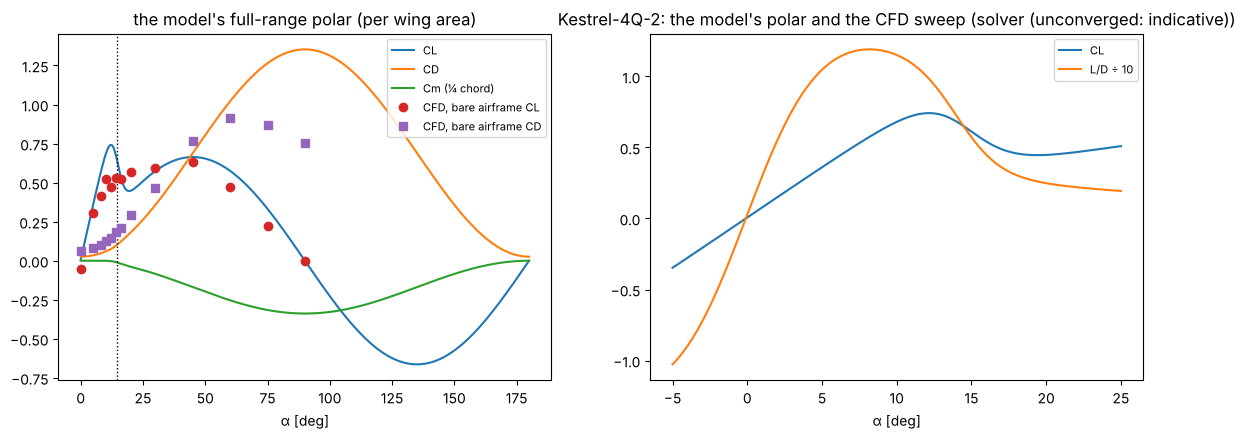

,Kestrel-4Q-1,Kestrel-4Q-2,Kestrel-4Q-3
"CL max, polar",0.81,1.033212,1.033212
"stall speed, polar [m/s]",10.910411,9.5593,9.5593
"cruise / stall, polar",1.466489,1.673763,1.673763
"CL max, CFD sweep (< 20°)",0.529298,0.528437,NaN
at α [deg],14.0,14.0,NaN
"stall speed, CFD [m/s]",13.496886,13.366697,NaN
"cruise / stall, CFD",1.185459,1.197005,NaN
CFD label,solver (unconverged: indicative),solver (unconverged: indicative),NOT RUN
CFD converged,0 of 13,1 of 13,NaN
wing area for cruise = 1.3 × stall on the CFD's CL max [m²],0.336722,0.330258,NaN


0.4

In [6]:
CFD = {v: kstu.cfd_sweep(SUMM["airframe_cfd"].get(v, {}).get("sweep"), SETS[v]) for v in VARIANTS}
for v, c in CFD.items():
    print(f"Kestrel-{v}: CFD sweep {c['label']}" + (f" — {c['n_converged']} of {c['n_bare']} bare cases converged; {c.get('quality')} quality; {c.get('provenance', {}).get('notebook') or 'workflow run'}" if c["n_bare"] else ""))
    if c["cmp"] is not None and len(c["cmp"]):
        display(c["cmp"].drop(columns=["note"]).astype({"α [deg]": float}).round(3).rename_axis(f"Kestrel-{v}: CFD [{c['label']}] against the model"))
        display(pd.DataFrame(c["numbers"]).round(3))
c = CFD[MAIN]
kd.polar_figure(S["pol"], c["rt"] if c["rt"] is not None and len(c["rt"]) else None); plt.title(f"Kestrel-{MAIN}: the model's polar" + (f" and the CFD sweep ({c['label']})" if c["n_bare"] else "")); plt.show()
STALL = kstu.stall_decision(SETS, CFD)
display(STALL.T)
CLOCK.lap("5 aerodynamics")

## 6. Trim, stability and control authority

No tail: the neutral point is the wing pair's aerodynamic centre moved by the pod (Raymer's fuselage term) and by the
four propellers ahead of the CG (De Young's normal-force slope, destabilising); the static margin is what the CG
leaves. Level flight needs a nose-up moment at positive lift: thrust alone trims by the lower pair pushing harder
than the upper, which fails once the drag is small (the upper pair would have to drop below idle) — then the elevons
trim. The hold point in the hover: the allocation matrix has full rank only with the diagonal pairs counter-rotating;
the heading lever is the reaction torque $\kappa T$ alone, the elevons in the slipstream multiply it.

In [7]:
display(pd.DataFrame({f"Kestrel-{v}": s["np"] for v, s in SETS.items()}).T.round(4).rename_axis("neutral point [lattice + empirical]"))
display(kstu.trim_table(S).round(3).rename_axis(f"Kestrel-{MAIN}: level flight and the trim [solver + empirical]"))
CT = kstu.control_table(S)
display(CT["rank"]); display(CT["hover authority"].round(3))
if "elevon authority" in CT:
    display(pd.Series(CT["elevon hinge"], name="elevon hinge moments").round(4).to_frame().T); display(CT["elevon authority"].round(3))
CLOCK.lap("6 trim")

,x_np_wings,x_np,Cma_wings,Cma_pod,Cma_props,Cma,static_margin,x_cg
neutral point [lattice + empirical],,,,,,,,
Kestrel-4Q-1,0.2331,0.2282,-0.5304,0.0665,0.0647,-0.3992,0.0955,0.2148
Kestrel-4Q-2,0.2331,0.2282,-0.5143,0.0665,0.0650,-0.3828,0.0916,0.2154
Kestrel-4Q-3,0.2331,0.2282,-0.5190,0.0665,0.0649,-0.3876,0.0927,0.2152


,CL,L/D,upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km],feasible
Kestrel-4Q-2: level flight and the trim [solver + empirical],,,,,,,,,
10.0,0.944,11.097,-0.018,0.747,False,41.102,57.036,34.222,True
12.0,0.656,12.062,-0.046,0.717,False,45.121,51.956,37.408,True
14.0,0.482,11.695,-0.036,0.728,False,51.161,45.823,38.491,True
16.0,0.369,10.599,-0.001,0.765,False,59.122,39.652,38.066,True
20.0,0.236,8.015,0.118,0.892,False,92.222,25.420,30.504,True
25.0,0.151,5.542,0.336,1.125,True,168.536,13.910,20.865,True


,senses (M1..M4),mirror-symmetric,rank,"σ (N, N·m)",condition,never produced,verdict
"diagonal pairs (M1, M4 | M2, M3)","(1, -1, -1, 1)",True,4,"2, 0.78, 0.28, 0.0323",61.907371,—,full control (thrust + 3 moments)
"side columns alike (M1, M3 | M2, M4)","(1, -1, 1, -1)",True,3,"2, 0.781, 0.28, 1.95e-16",inf,+1.00·L + -0.04·N,NOT controllable in the hover
"rows alike (M1, M2 | M3, M4)","(1, 1, -1, -1)",False,3,"2, 0.78, 0.282, 6.97e-17",inf,+0.00·T + -1.00·L + +0.12·M,NOT controllable in the hover
all the same way,"(1, 1, 1, 1)",False,3,"2, 0.78, 0.28, 5.39e-17",inf,-0.02·T + -1.00·L,NOT controllable in the hover


,most negative [N·m],most positive [N·m],inertia [kg·m²],angular acceleration [rad/s²]
about the thrust axis (hover heading / cruise roll),-0.237,0.237,0.113,2.094
about y (pitch-over / cruise pitch),-2.201,2.053,0.023,88.384
about z (hover tilt sideways / cruise yaw),-5.718,5.718,0.104,54.985


,V [m/s],"elevon area, one [m²]",elevon chord [m],hinge moment [N·m],"hinge moment, hover slipstream [N·m]",slipstream speed in the hover [m/s],servo torque rating [N·m],"servo margin, cruise","servo margin, hover",time to 20° [s]
elevon hinge moments,16.0,0.0088,0.0392,-0.0121,-0.0067,12.8484,0.17,14.0916,25.329,0.04


,one elevon ΔL [N],roll / heading from elevons [N·m],pitch from elevons [N·m],rotors: about the thrust axis [N·m],rotors: pitch [N·m],"elevons / rotors, about the axis"
hover (slipstream only),2.572,3.987,0.706,0.237,2.053,16.835
cruise 16 m/s,4.090,6.339,1.122,0.394,2.053,16.086


0.8

## 7. Performance and energy

Level flight against airspeed: drag, the rotors' full thrust falling with the inflow and where it meets the drag
(the thrust-limited maximum speed — the 9×6's pitch speed, not the drag, sets it), the electrical power, endurance and
range on 80 % of the battery; specific excess power $P_s = (T - D)\,V/W$ for the climb; the turn at the corner speed
where the lift limit meets the 4 g structural limit; the horizontal-plane authority. The energy budget charges the
hover for take-off, landing and the transitions before the cruise. **Method: solver (BEMT, lattice) + empirical
(build-up, ±20 % on Cd0 → ±15 % on endurance).**

,Kestrel-4Q-1,Kestrel-4Q-2,Kestrel-4Q-3
pursuit table,,,
mass [kg],1.69,1.65,1.65
Cd0,0.07,0.03,0.03
stall speed [m/s],10.91,9.56,9.56
"V max, thrust = drag [m/s]",30.09,33.28,33.28
accelerate 13 → 25 m/s [s],0.95,0.80,0.80
accelerate 13 → 0.9 V max [s],1.34,1.57,1.57
best climb rate [m/s],28.15,30.94,30.94
at climb speed [m/s],16.50,18.00,18.00
steepest climb [deg],90.00,90.00,90.00


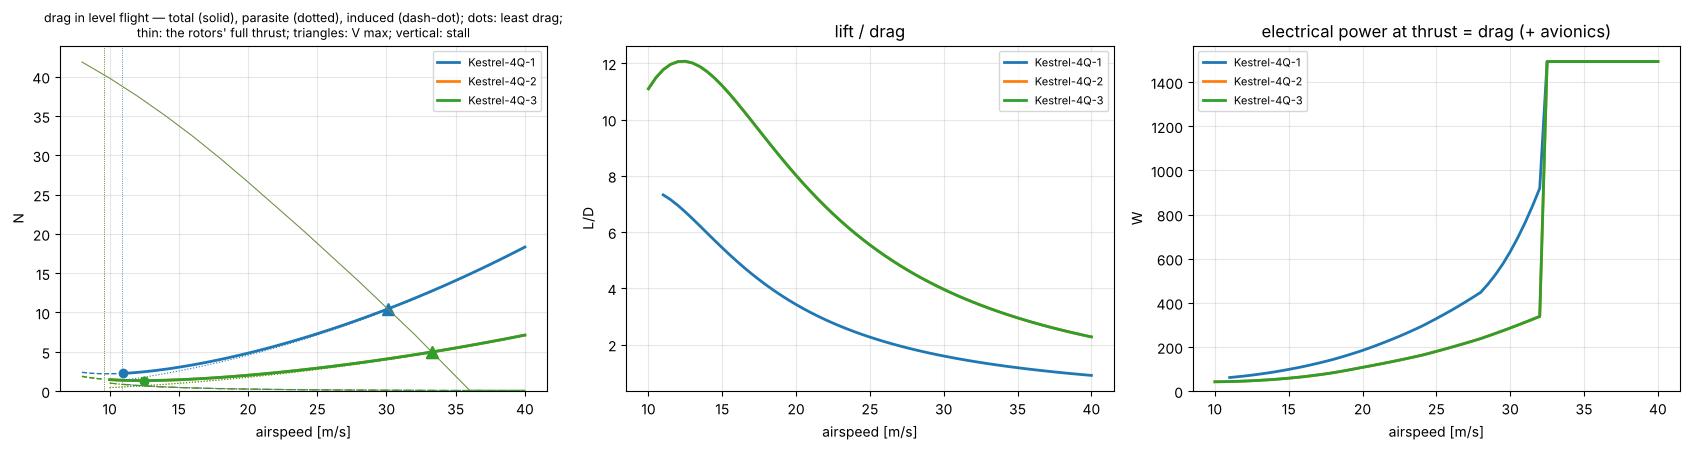

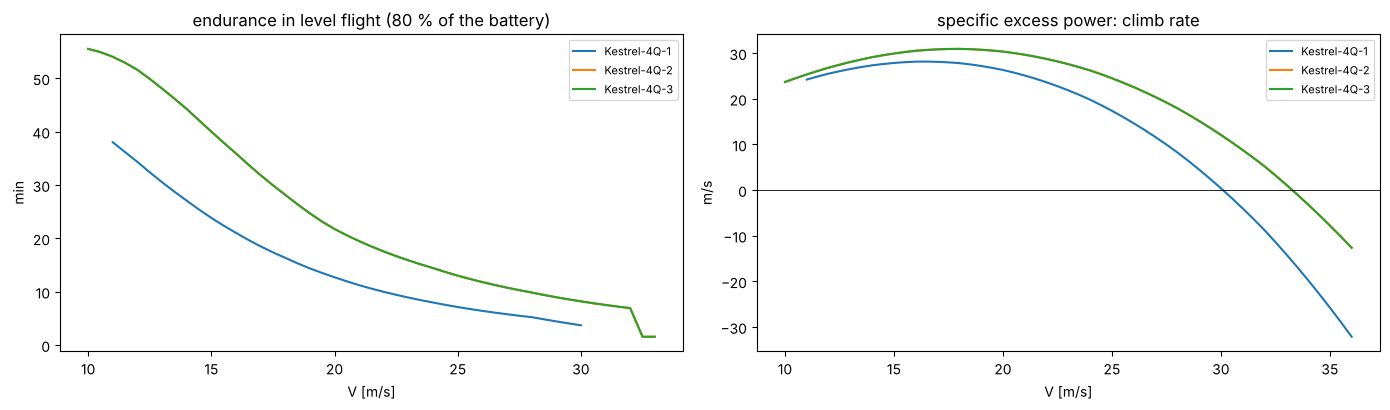

,Kestrel-4Q-2: energy budget
usable energy [Wh],39.07
"hover, 1.5 min (take-off, landing, transitions) [Wh]",5.35
hover power [W],213.99
cruise power at 16 m/s [W],59.12
cruise time on the rest [min],34.22
best-endurance speed [m/s],10.00
power there [W],41.10
loiter time on the rest [min],49.23
range at 16 m/s on the rest [km],32.85


0.8

In [8]:
PERF = kstu.performance(SETS)
display(PERF["pursuit"].astype(float).round(2).rename_axis("pursuit table"))
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
kd.drag_vs_speed({f"Kestrel-{v}": s["veh"] for v, s in SETS.items()}, speeds=np.arange(8.0, 40.5, 0.5), axs=axs); plt.tight_layout(); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for n, pf in PERF["perfs"].items():
    t = pf["table"]; axs[0].plot(t.index, t["endurance [min]"], label=n); axs[1].plot(t.index, t["P_s (climb rate) [m/s]"], label=n)
axs[0].set(xlabel="V [m/s]", ylabel="min", title="endurance in level flight (80 % of the battery)"); axs[1].set(xlabel="V [m/s]", ylabel="m/s", title="specific excess power: climb rate"); axs[1].axhline(0, color="k", lw=0.6)
for a_ in axs: a_.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.Series(kstu.energy_budget(S), name=f"Kestrel-{MAIN}: energy budget").round(2).to_frame())
CLOCK.lap("7 performance")

## 8. Structure

**Screening (analytic).** The front view as a plane frame at a 4 g pull-up: the spars as beams clamped at the pod,
the posts and diagonals as pin-ended bars, the lift elliptic less the wings' and motors' inertia — even, and with the
upper wing carrying 75 % (one wing stalling first); the spar stress $\sigma = M c / I$ and its reserve against the
tube's allowable, Euler buckling of the struts, the propeller gap's change; the motor stations' stiffness and first
modes per bracing against the pitch loop's bandwidth and the rotor's 1P; the aircraft standing on its feet in wind.

**FEA (solver), where on file.** The same frame as solid tubes in CalculiX under the same loads at ultimate (× 1.5) —
A the pull-up, B the 75 % wing, C the heading manoeuvre's torsion, the modes — and the printed spar–post joint with
its across-layer tension; read against the plane frame's numbers. Produced by `side_labs/kestrel/structure_fea.py`;
NOT RUN here means exactly that.

In [9]:
ST = kstu.structure_screen(S)
display(ST["even lift"].round(3).rename_axis("plane frame, 4 g, even lift [analytic]")); display(ST["upper wing 75 %"].round(3).rename_axis("plane frame, 4 g, upper wing 75 % [analytic]"))
display(ST["modes"].round(2)); print("references:", {k: round(v, 2) for k, v in ST["modes"].attrs["references"].items()})
display(pd.Series({k: v for k, v in ST["stance"].items() if k != "edges"}, name="standing on the feet [analytic]").round(2).to_frame().T)
FEA_SUM = SUMM["structure_fea"].get(MAIN)
FEAT = kstu.fea_table(FEA_SUM)
if FEAT is None:
    print(f"FEA of Kestrel-{MAIN}: NOT RUN — {kcp.command('structure_fea', variant=MAIN, campaign='all')}\n  the plane frame's reserves above stand in (analytic); nothing below is a strength verdict")
    display(ST["reference"].astype({c: float for c in ST["reference"].columns if c not in ("bracing", "case")}).round(2).rename_axis("plane frame reference the FEA will be read against"))
else:
    print(f"FEA of Kestrel-{MAIN} [solver]: {FEA_SUM['counts']}")
    display(FEAT)
    cmpf = kstu.fea_against_frame(FEA_SUM, S)
    if cmpf is not None:
        display(cmpf.astype(float).round(2).rename_axis("FEA against the plane frame"))
CLOCK.lap("8 structure")

,spar peak moment [N·m],spar stress [MPa],spar reserve,"tip deflection, upper [mm]","tip deflection, lower [mm]","motor station, upper [mm]","motor station, lower [mm]",propeller gap change [mm],propeller gap under load [mm],least buckling margin,truss mass [g]
"plane frame, 4 g, even lift [analytic]",,,,,,,,,,,
posts + X diagonals,0.646,11.142,35.899,-0.089,-0.089,0.034,0.034,0.0,51.4,85.037,127.221
posts only,1.180,20.359,19.647,1.796,1.796,1.355,1.355,-0.0,51.4,inf,40.800
no truss (two cantilevers),1.180,20.359,19.647,1.796,1.796,1.355,1.355,0.0,51.4,inf,0.000


,spar peak moment [N·m],spar stress [MPa],spar reserve,"tip deflection, upper [mm]","tip deflection, lower [mm]","motor station, upper [mm]","motor station, lower [mm]",propeller gap change [mm],propeller gap under load [mm],least buckling margin,truss mass [g]
"plane frame, 4 g, upper wing 75 % [analytic]",,,,,,,,,,,
posts + X diagonals,0.711,12.271,32.596,-0.143,-0.035,0.034,0.034,-0.000,51.400,587.353,127.221
posts only,1.500,25.885,15.453,1.725,1.867,1.356,1.355,0.001,51.401,inf,40.800
no truss (two cantilevers),2.907,50.152,7.976,6.103,-2.510,4.431,-1.721,6.152,57.552,inf,0.000


,k symmetric [N/mm],k antisymmetric [N/mm],"first mode, symmetric [Hz]","first mode, antisymmetric [Hz]"
posts + X diagonals,326.82,12950.83,260.53,1640.06
posts only,1.17,12567.54,15.61,1615.61
no truss (two cantilevers),1.17,1.17,15.61,15.61


references: {'rotor 1P in the hover [Hz]': 110.0, 'pitch loop bandwidth [Hz]': 1.91}


,CG height above the ground [m],least tip-over angle [deg],"wind that tips it, broadside [m/s]","wind that tips it, edge-on [m/s]",touchdown load [N],"per foot, two feet first [N]",foot rod Euler load [N],"foot rod margin, two feet first"
standing on the feet [analytic],0.32,39.38,8.81,20.92,119.39,59.69,766.45,12.84


FEA of Kestrel-4Q-2: NOT RUN — .venv/bin/python side_labs/kestrel/structure_fea.py --variant 4Q-2 --chapter all
  the plane frame's reserves above stand in (analytic); nothing below is a strength verdict


,bracing,case,"spar stress, limit [MPa]","spar stress, ultimate [MPa]","tip deflection, upper, limit [mm]","tip deflection, ultimate [mm]",spar reserve (limit),"first mode, symmetric [Hz]","first mode, antisymmetric [Hz]"
plane frame reference the FEA will be read against,,,,,,,,,
frame_x_A,x,A,11.14,16.71,-0.09,-0.13,35.90,NaN,NaN
frame_x_B,x,B,12.27,18.41,-0.14,-0.21,32.60,NaN,NaN
frame_x_modes,x,modes,NaN,NaN,NaN,NaN,NaN,260.53,1640.06
frame_posts_A,posts,A,20.36,30.54,1.80,2.69,19.65,NaN,NaN
frame_posts_B,posts,B,25.89,38.83,1.73,2.59,15.45,NaN,NaN
frame_posts_modes,posts,modes,NaN,NaN,NaN,NaN,NaN,15.61,1615.61
frame_none_A,none,A,20.36,30.54,1.80,2.69,19.65,NaN,NaN
frame_none_B,none,B,50.15,75.23,6.10,9.15,7.98,NaN,NaN
frame_none_modes,none,modes,NaN,NaN,NaN,NaN,NaN,15.61,15.61


0.1

## 9. The transitions — hover to cruise and back, through the stall

`kestrel_transition` flies the aircraft in the pitch plane: each wing split into the span blown by its propellers
(Glauert's slipstream adds $\Delta v$ along the body axis) and the free-stream span, the Viterna polar beyond the
stall, a pitch PID scheduled on airspeed, the height held by the collective, the moment allocated to differential
thrust and the elevons, roll checked against one side's free-stream span stalling first. **Method: reduced-order
model (solver)** — its post-stall aerodynamics are the Viterna blend, so its verdicts are comparisons between
variants and remedies, not certified trajectories; the blown stalled regime is what the CFD `transitions` campaign is
for. The criteria: height within 3 m below and 10 m above the start on the way back, pitch within 10°, roll demand
within the authority, no divergence.

Only the decision-relevant episodes are flown (each is ~8 s): every variant forward and back at the 3 s schedule in
still air and back into a 6 m/s headwind; 4Q-2 and 4Q-3 back with the remedies notebook 42 found (reverse thrust on the
lower pair, the crow brake with it); the main variant again on the CFD's correction when a sweep is on file.

CFD correction for Kestrel-4Q-2: from the sweep (13 points, solver (unconverged: indicative))


height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  least pitch margin  peak rotor thrust / T_max  elevon max [deg]  \
vehicle      direction case                                                                                                                                                                                        
Kestrel-4Q-1 forward   as is, still air                             0.11             0.39                   2.46                           0.95                0.82                       0.55              4.19   
             back      as is, still air                             0.55             2.44                   4.65                           1.50                0.77                       0.44              5.76   
                       as is, headwind 6 m/s                        0.19             2.44                   4.65                           1.50                0.77                       0.47              5.76   
Kestrel-4Q-2 forward   as is, still air                             0.13             0.41                   2.45                           0.81                0.84                       0.53              3.77   
             back      as is, still air                             0.17            12.33                   3.44                           1.35                0.82                       0.36              4.55   
                       as is, headwind 6 m/s                        0.17            12.33                   3.44                           1.35                0.82                       0.37              4.55   
Kestrel-4Q-3 forward   as is, still air                             0.14             0.41                   2.46                           0.82                0.85                       0.53              3.68   
             back      as is, still air                             0.18            11.88                   3.55                           1.35                0.82                       0.37              4.42   
                       as is, headwind 6 m/s                        0.18            11.88                   3.55                           1.35                0.82                       0.37              4.42   
Kestrel-4Q-2 back      reverse thrust 3 N per rotor                 0.44             0.24                   4.10                           1.32                0.85                       0.41              3.71   
                       crow brake ±20° + reverse thrust             0.41             0.21                   3.97                           1.35                0.85                       0.40              3.71   
Kestrel-4Q-3 back      reverse thrust 3 N per rotor                 0.46             0.21                   4.12                           1.33                0.85                       0.41              3.55   
                       crow brake ±20° + reverse thrust             0.42             0.18                   3.97                           1.36                0.85                       0.40              3.55   
Kestrel-4Q-2 forward   as is, CFD sweep correction                  0.50             0.40                   2.50                           0.85                0.81                       0.54              4.54   
             back      as is, CFD sweep correction                  0.40             0.27                   3.83                           1.39                0.84                       0.42              4.05   

                                                         roll demand / authority  energy [Wh]   pass                                                method  
vehicle      direction case                                                                                                                                 
Kestrel-4Q-1 forward   as is, still air                                     0.07         0.53   True                          reduced-orde

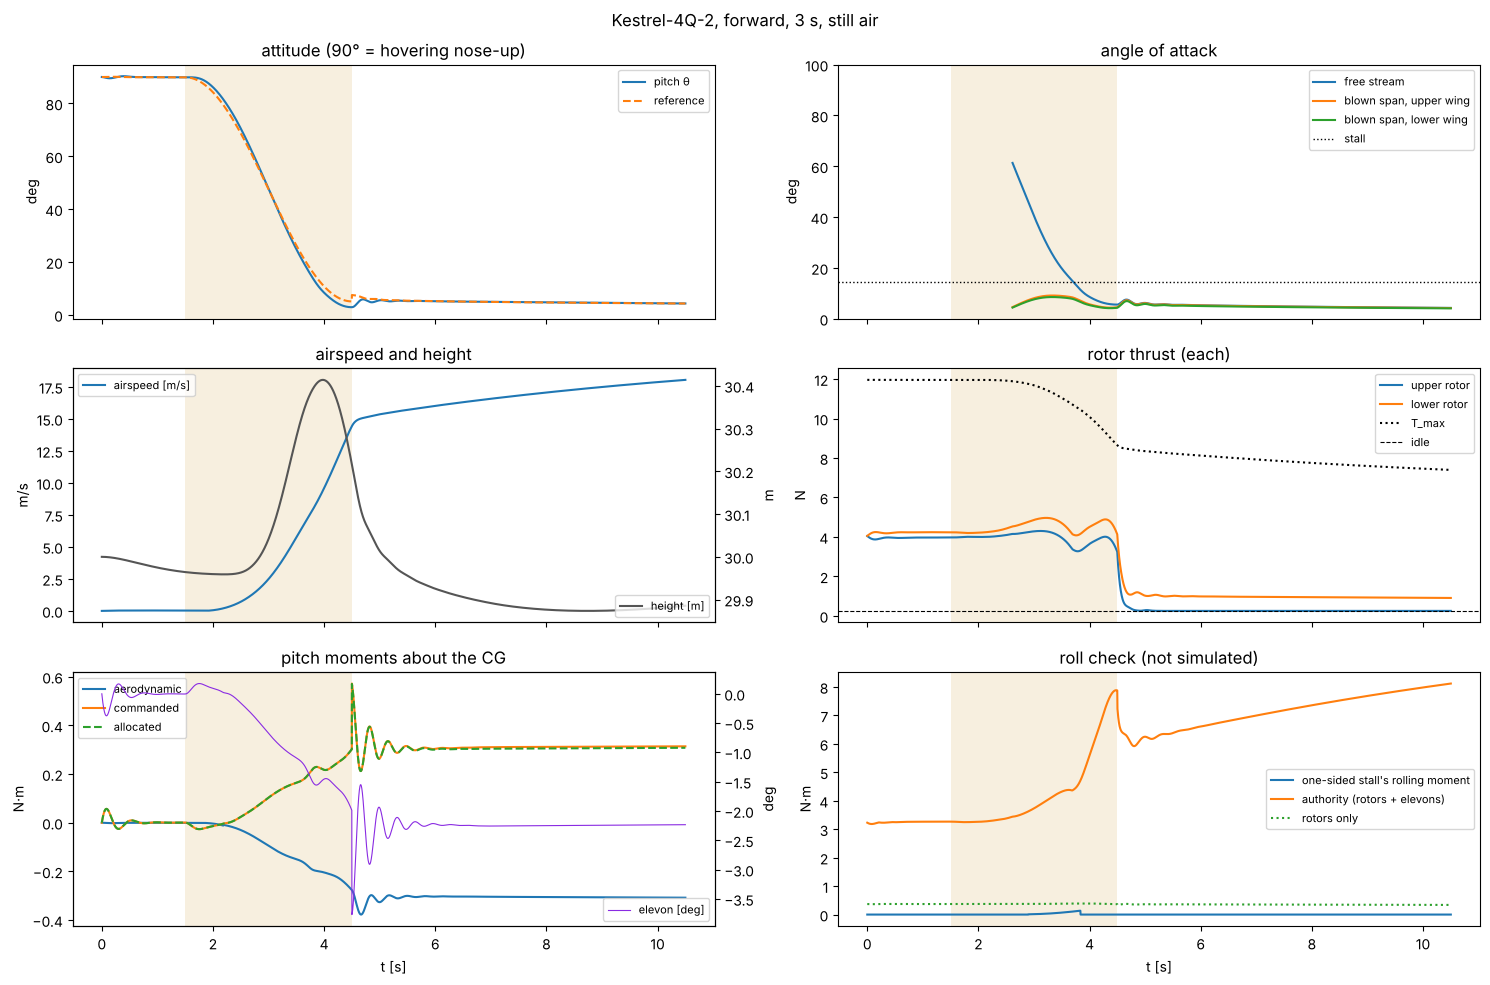

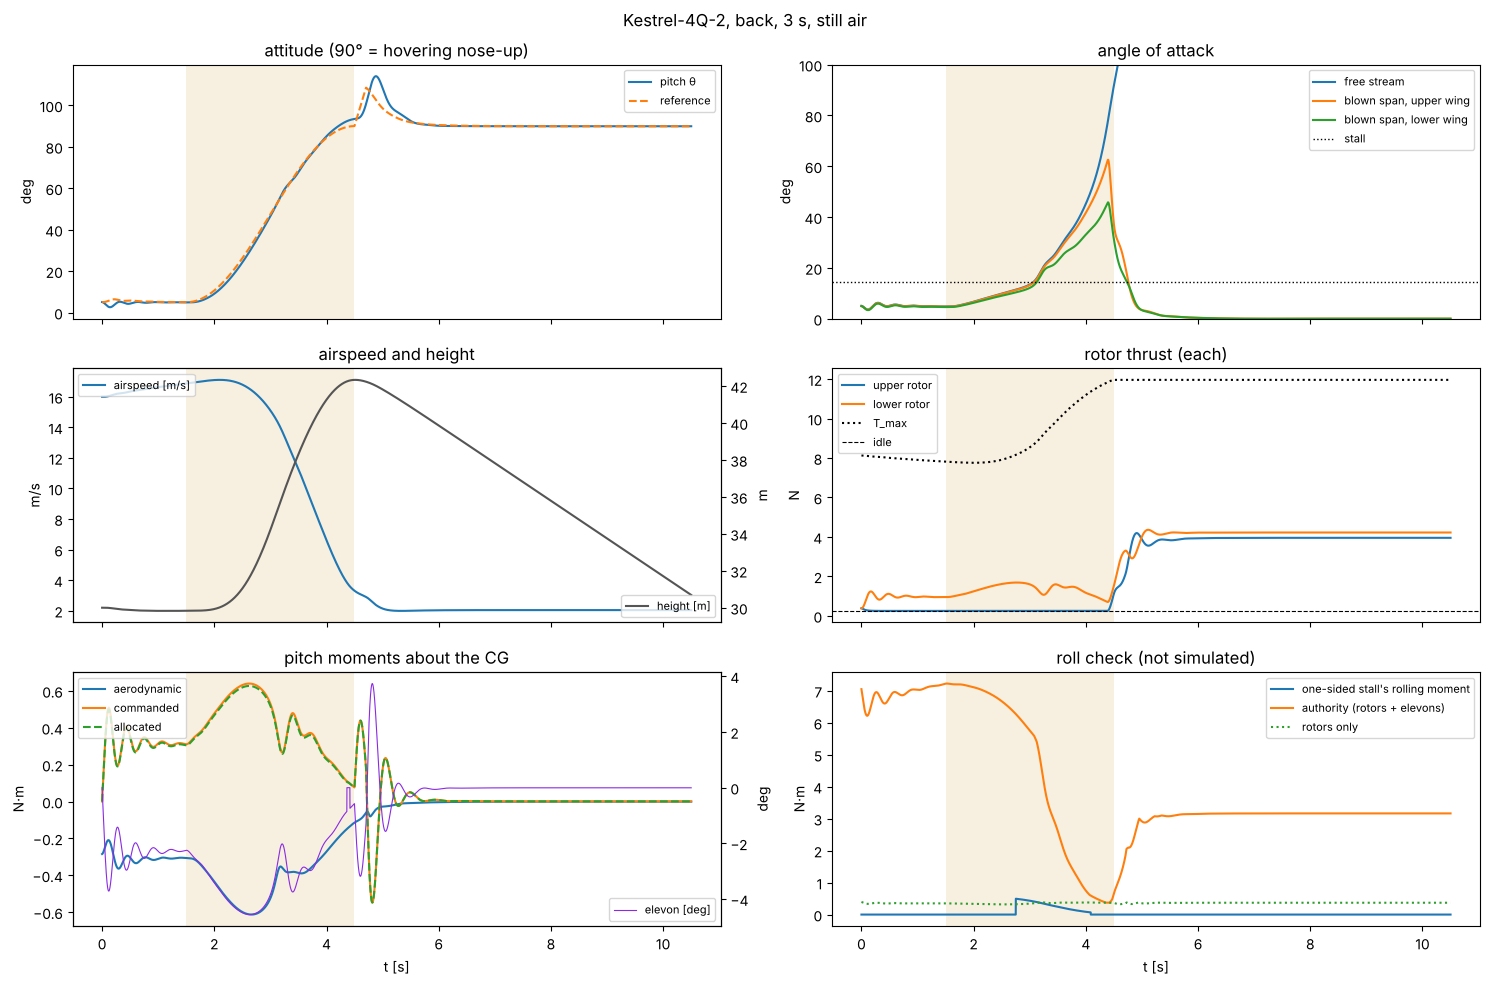

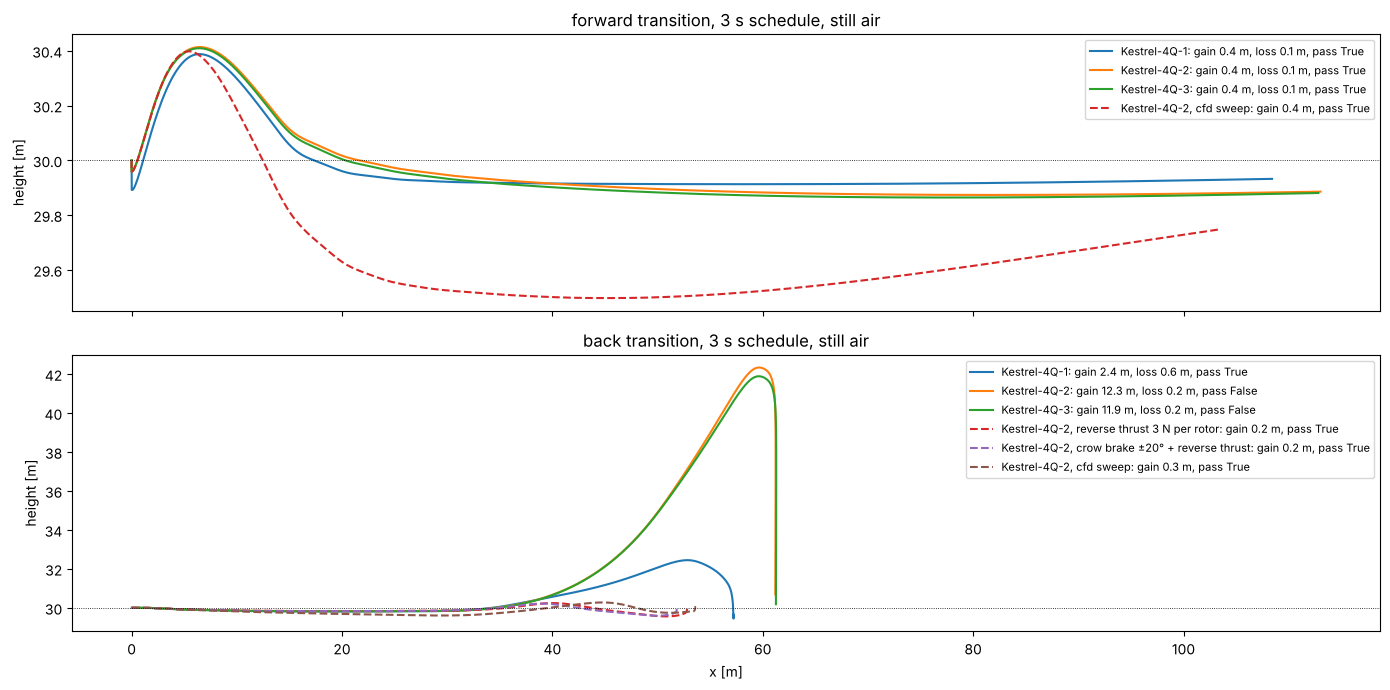

from [m/s] to [m/s] time [s] distance [m] energy [Wh] reached mean deceleration [m/s²]
vehicle      level deceleration 16 → 13 m/s                                                                                       
Kestrel-4Q-1 rotors at idle                       16.0     13.0     2.68    38.560274    0.032011    True                 1.119403
Kestrel-4Q-2 rotors at idle                       16.0     13.0    11.96   172.132993    0.142815    True                 0.250836
             crow brake ±20°                      16.0     13.0     1.86    26.754018    0.022218    True                 1.612903
             reverse thrust 3 N                   16.0     13.0     0.37     5.347234    0.032209    True                 8.108108
Kestrel-4Q-3 rotors at idle                       16.0     13.0    11.96   172.132993    0.142815    True                 0.250836
             crow brake ±20°                      16.0     13.0      1.7    24.451668    0.020308    True                 1.764706
             reverse thrust 3 N                   16.0     13.0     0.37     5.347234    0.032209    True                 8.108108

111.8

In [10]:
CORR = kcp.airframe_correction(SUMM["airframe_cfd"].get(MAIN, {}).get("sweep") or {}, S["veh"], source="sweep") if SUMM["airframe_cfd"].get(MAIN) else None
if CORR is not None:
    print(f"CFD correction for Kestrel-{MAIN}: from the {CORR.source} ({len(CORR.samples)} points, {CFD[MAIN]['label']})")
TR = kstu.transitions(SETS, main=MAIN, cfd_correction=CORR)
TRT = kstu.transition_columns(TR["table"])
display(TRT.round(2))
for kind in ("forward", "back"):
    kd.episode_figure(TR["episodes"][(MAIN, kind, "as is, still air")], S["veh"], title=f"Kestrel-{MAIN}, {kind}, 3 s, still air"); plt.savefig(OUT / f"{MAIN}_{kind}_3s.png", dpi=110, bbox_inches="tight"); plt.show()
fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, kind in zip(axs, ("forward", "back")):
    for v in VARIANTS:
        ep = TR["episodes"][(v, kind, "as is, still air")]
        ax.plot(ep.log["X"], ep.log["Z"], label=f"Kestrel-{v}: gain {ep.metrics['height gain [m]']:.1f} m, loss {ep.metrics['height loss [m]']:.1f} m, pass {ep.metrics['pass']}")
    for key in [k for k in TR["episodes"] if k[0] == MAIN and k[1] == kind and not k[2].startswith("as is")]:
        ep = TR["episodes"][key]; ax.plot(ep.log["X"], ep.log["Z"], "--", label=f"Kestrel-{MAIN}, {key[2]}: gain {ep.metrics['height gain [m]']:.1f} m, pass {ep.metrics['pass']}")
    ax.axhline(30, color="k", lw=0.6, ls=":"); ax.set(ylabel="height [m]", title=f"{kind} transition, 3 s schedule, still air"); ax.legend(fontsize=8)
axs[1].set_xlabel("x [m]"); plt.tight_layout(); plt.savefig(OUT / "paths.png", dpi=110); plt.show()
DEC = kstu.deceleration(SETS)
display(DEC.round(2).rename_axis(["vehicle", f"level deceleration {kf.V_CRUISE:g} → 13 m/s"]))
CLOCK.lap("9 transitions")

## 10. Which workflows to run next

The screening above says which solver cases change a decision. They are listed with their reasons and commands; an
engineer launches them from a shell (detached: `nohup … &` or `tmux`, then `tail -F <run>/run.log`), and points `RUNS`
at the run directory each prints. Compatible results are reused, never recomputed: a run whose fingerprint matches the
design stays valid until the CAD parameters, the mass or the propeller calibration change.

In [11]:
REC = kstu.recommended_campaigns(SETS, CFD, SUMM["structure_fea"], main=MAIN, interference_summary=SUMM["airframe_cfd"].get(MAIN, {}).get("interference"))
display(REC.drop(columns=["command"]))
print("\n".join(f"{i}. {r['command']}" for i, r in REC.iterrows()))
CLOCK.lap("10 recommendations")

,workflow,variant,campaign,quality,why
order,,,,,
2,airframe_cfd,4Q-2,stall,fine,CL max decides the stall speed and the wing area: the polar stalls at 14°; the screening sweep (if any) wa...
3,airframe_cfd,4Q-2,cruise,screening,the level cruise and the stall point with the rotor disks on: the blown spans' lift and the trim
4,structure_fea,4Q-2,all,—,the frame's margins at ultimate and the joint's across-layer tension: no FEA on file
5,airframe_cfd,4Q-2,transitions,screening,"the transition points with the disks (the model's least-known regime: blown, stalled); only after the bare..."


2. .venv/bin/python side_labs/kestrel/airframe_cfd.py --variant 4Q-2 --chapter stall --quality fine
3. .venv/bin/python side_labs/kestrel/airframe_cfd.py --variant 4Q-2 --chapter cruise --quality screening
4. .venv/bin/python side_labs/kestrel/structure_fea.py --variant 4Q-2 --chapter all
5. .venv/bin/python side_labs/kestrel/airframe_cfd.py --variant 4Q-2 --chapter transitions --quality screening


0.0

## 11. Final assessment

The checks of the main variant against the study's targets, each with the method behind it; the verdict lines are
written from the numbers above. A screening pass (`KESTREL_SCREENING=1`) is labelled unvalidated. The runtime of this
notebook is measured, not claimed, and exported with the report.

In [12]:
ASSESS = kstu.assessment(SETS, CFD, SUMM["structure_fea"], TR, PERF, main=MAIN, screening=SCREENING)
display(ASSESS["table"])
print("\n".join(ASSESS["lines"]))
display(kstu.variants_table(SETS).T)
CLOCK.lap("11 assessment")
RT = CLOCK.frame(); display(RT.T)
print(f"measured runtime: {CLOCK.total():.0f} s on {os.uname().nodename} ({os.cpu_count()} CPUs) — the workflow threshold is {kstu.WORKFLOW_THRESHOLD_MIN[0]}–{kstu.WORKFLOW_THRESHOLD_MIN[1]} min")

Kestrel-4Q-2 — final checks,value,target,holds,note
check,,,,
take-off mass [kg],1.65,≤ 2,✔,mass table: component data + assumed structure densities (estimate)
hover thrust / weight,2.95,≥ 2,✔,"Boreas BEMT, generic section unless prop_lab is on file (solver)"
static margin [chords],0.0916,0.05 – 0.15,✔,lattice + De Young propellers (solver + empirical)
stall speed / cruise speed,0.597,≤ 0.8,✔,"polar's CL max 1.03 (NeuralFoil ×0.9, empirical)"
endurance at the cruise [min],39.7,≥ 20,✔,"drag build-up + BEMT (solver + empirical, ±20 % on Cd0)"
"forward transitions pass (nominal, still air)",yes,== yes,✔,reduced-order model (solver); Viterna post-stall
back transitions pass as is (still air and headwind),no,== yes,✘,reduced-order model (solver)
a back-transition remedy passes,yes,== yes,✔,reverse thrust / crow brake in the model (solver); the drives' reverse thrust is an assumption until prop_...
CFD sweep: lift slope / lattice,0.83,0.85 – 1.15,✘,solver (unconverged: indicative); 1 of 13 converged


Kestrel-4Q-2: 7 of 11 checks hold (screening pass: unvalidated — CFD and FEA labelled NOT RUN where missing).
Mass 1.65 kg, static margin 0.092 c, hover T/W 2.95 at 214 W; cruise 16 m/s at 59 W for 40 min (L/D 10.6); stall 9.6 m/s on the polar's CL max 1.03.
The CFD sweep (solver (unconverged: indicative)) reads CL max 0.53 below 20° against the polar's 1.03: if it holds, the stall is 13.4 m/s and the cruise only 1.20 × it — the fine stall campaign decides the wing area.
Transitions (reduced-order model): forward pass; back as is FAIL; with a remedy pass.
FEA: NOT RUN — the plane frame's spar reserve stands in.
Pursuit: V max 33.3 m/s (thrust-limited), corner radius 9.6 m, best climb 30.9 m/s.


,Kestrel-4Q-1,Kestrel-4Q-2,Kestrel-4Q-3
take-off mass [kg],1.686206,1.651145,1.651145
CG x [mm],214.848127,215.399514,215.236718
static margin [chords],0.095525,0.091586,0.092749
Cd0,0.066549,0.02574,0.02574
CL max (polar),0.81,1.033212,1.033212
stall speed [m/s],10.910411,9.5593,9.5593
stall / cruise,0.681901,0.597456,0.597456
hover T/W,2.893213,2.954649,2.954649
hover electrical [W],220.648811,213.991442,213.991442
L/D at 16 m/s,4.956276,10.599409,10.599409


,1 prerequisites,2 geometry,3 mass,4 propulsion,5 aerodynamics,6 trim,7 performance,8 structure,9 transitions,10 recommendations,11 assessment,total
seconds,1.7,13.5,0.0,0.4,0.4,0.8,0.8,0.1,111.8,0.0,0.0,129.5


measured runtime: 130 s on vm (4 CPUs) — the workflow threshold is 15–30 min


### Export

The numbers as JSON (`designs/data/reports/43_kestrel_study.json`) and Markdown, stitched into the dossier
`designs/data/kestrel_dossier.json` / `.md` — paste the JSON into a conversation and the design continues from it.

In [13]:
REPORT = {"prerequisites": PREREQ, "parameters that differ": pd.DataFrame({f"Kestrel-{v}": d for v, d in diff.items()}), "layout [m, m²]": lay, "mass groups [kg]": kstu.mass_groups(SETS),
          "mass, CG, inertia (main)": {k: v for k, v in CI.items() if k != "I"}, "hover (Boreas)": pd.DataFrame({f"Kestrel-{v}": s["hover"] for v, s in SETS.items()}).T,
          "hover (momentum theory)": kstu.hover_analytic(S), "correlations": kstu.correlations_table(), "biplane check": kstu.biplane_check(A, L), "wing interference": INT["table"], "wing interference, gap sweep": INT["analytic"]["sweep"],
          "monoplane equivalents": INT["analytic"]["equivalents"], "machines scaled to Kestrel": CMP["table"], "drag areas [cm²]": dtab,
          "polars": pd.DataFrame({f"Kestrel-{v}": s["pol"].__dict__ for v, s in SETS.items()}).T,
          "CFD sweep against the model": {v: c["cmp"] for v, c in CFD.items() if c["cmp"] is not None}, "CFD sweep numbers": {v: c["numbers"] for v, c in CFD.items() if c["numbers"]},
          "CFD labels": {v: {"label": c["label"], "bare cases": c["n_bare"], "converged": c["n_converged"]} for v, c in CFD.items()}, "stall decision": STALL,
          "neutral point": pd.DataFrame({f"Kestrel-{v}": s["np"] for v, s in SETS.items()}).T, "trim (main)": kstu.trim_table(S), "allocation rank": CT["rank"], "hover authority": CT["hover authority"],
          "pursuit": PERF["pursuit"], "energy budget (main)": kstu.energy_budget(S), "plane frame, even lift": ST["even lift"], "plane frame, 75 % wing": ST["upper wing 75 %"], "stiffness and modes": ST["modes"],
          "ground stance": {k: v for k, v in ST["stance"].items() if k != "edges"}, "FEA": FEAT if FEAT is not None else "NOT RUN", "transitions": TRT, "level deceleration": DEC,
          "recommended workflows": REC, "final checks": ASSESS["table"], "verdict": ASSESS["lines"], "variants": kstu.variants_table(SETS), "runtime [s]": RT, "status": {"screening": SCREENING, "required": sorted(map(str, REQUIRED))}}
EXP = kr.export(kstu.NAME, "Kestrel — the design study (notebook 43)", REPORT, meta={"main": MAIN, "mass [kg]": CI["mass_kg"], "runtime_s": CLOCK.total(), "screening": SCREENING,
                                                                                    "CFD": {v: c["label"] for v, c in CFD.items()}, "FEA": "on file" if FEAT is not None else "NOT RUN"})
print("JSON report:", EXP["json"], f"({EXP['json_kB']} kB) | dossier:", EXP["dossier_json"], f"({EXP['dossier_json_kB']} kB) | Markdown:", EXP["markdown"])


JSON report: /home/user/vegeta/designs/data/reports/43_kestrel_study.json (63.1 kB) | dossier: /home/user/vegeta/designs/data/kestrel_dossier.json (332.7 kB) | Markdown: /home/user/vegeta/designs/data/reports/43_kestrel_study.md
